# Seoul Public Bicycle Rental Patterns and Principal Component Analysis

**Course:** CDS 303  
**Study area and period:** Seoul, January 1–June 30, 2026  
**Research question:** How do bicycle rental patterns vary across time periods, weather conditions, and rental stations in Seoul, and what underlying dimensions of usage variation can Principal Component Analysis (PCA) reveal?

## Study design

The analysis examines **temporal patterns** and **station-level differences**, then uses PCA to identify interpretable dimensions of station usage. Citywide weather is a **secondary descriptive comparison** and is not included in PCA. The six-month study period overlaps a strong winter-to-summer transition, so weather associations cannot be separated reliably from seasonality using these comparisons.

**Analysis sequence:** Dataset descriptions and quality checks → station-level features → descriptive comparisons → PCA → interpretation of findings.

### Data sources

| Dataset | Role in this study |
|---|---|
| [Seoul Ttareungi rental history (OA-15182)](https://data.seoul.go.kr/dataList/OA-15182/A/1/datasetView.do), combined January–June 2026 CSV | Primary record-level source for station features, time trends, and PCA |
| [Seoul daily rental counts (OA-14994)](https://data.seoul.go.kr/dataList/OA-14994/A/1/datasetView.do), January–June 2026 CSV | Independent published daily count series used for source comparison |
| Korea Meteorological Administration, Seoul ASOS station 108, January–June 2026 | Secondary descriptive weather context, not a PCA input |
| Seoul Ttareungi station locations (`station_locations.csv`) | Station-ID and coordinate validation only; spatial coordinates excluded from PCA |

An English station-name lookup is derived from the rental-history file, rather than being a separate observation dataset. The analysis is restricted to January–June 2026.


In [1]:
import pandas as pd

### English Translation Setup

The source files from the Seoul Open Data Portal use Korean column names, and a few columns use Korean category values or Korean place names. Everything below is translated to English immediately after loading, so every table and output in this notebook — from here on — is in English.

**Columns**

| Korean | English |
|---|---|
| 자전거번호 | bike_id |
| 대여일시 | rental_datetime |
| 대여 대여소번호 | rental_station_number |
| 대여 대여소명 | rental_station_name_kr |
| 대여거치대 | rental_dock_number |
| 반납일시 | return_datetime |
| 반납대여소번호 | return_station_number |
| 반납대여소명 | return_station_name_kr |
| 반납거치대 | return_dock_number |
| 이용시간(분) | duration_min |
| 이용거리(M) | distance_m |
| 생년 | birth_year |
| 성별 | gender |
| 이용자종류 | user_type |
| 대여대여소ID | rental_station_id |
| 반납대여소ID | return_station_id |
| 대여일자 (daily summary file) | rental_date |
| 대여건수 (daily summary file) | rental_count |

**Category values**: 내국인 → Domestic, 외국인 → Foreigner, 비회원 → Non-member; M/m → Male, F/f → Female.

**Station names** are Korean place names (subway exits, landmarks), so rather than a meaning-based "translation" we romanize them — the same Korean-to-Latin-alphabet spelling system used on Korean street signs — computed directly from the Hangul characters below (no external service, works for all 2,761 stations).

In [2]:
## English column-name and category-value mappings
COLUMN_TRANSLATIONS = {
    "자전거번호": "bike_id",
    "대여일시": "rental_datetime",
    "대여 대여소번호": "rental_station_number",
    "대여 대여소명": "rental_station_name_kr",
    "대여거치대": "rental_dock_number",
    "반납일시": "return_datetime",
    "반납대여소번호": "return_station_number",
    "반납대여소명": "return_station_name_kr",
    "반납거치대": "return_dock_number",
    "이용시간(분)": "duration_min",
    "이용거리(M)": "distance_m",
    "생년": "birth_year",
    "성별": "gender",
    "이용자종류": "user_type",
    "대여대여소ID": "rental_station_id",
    "반납대여소ID": "return_station_id",
    "대여일자": "rental_date",
    "대여건수": "rental_count",
    "지점": "station_id",
    "지점명": "station_name_kr",
    "일시": "date",
    "평균기온(°C)": "avg_temp_c",
    "최저기온(°C)": "min_temp_c",
    "최고기온(°C)": "max_temp_c",
    "일강수량(mm)": "precip_mm",
    "평균 풍속(m/s)": "avg_wind_mps",
    "평균 상대습도(%)": "avg_humidity_pct",
    "합계 일조시간(hr)": "sunshine_hr",
}

GENDER_MAP = {"M": "Male", "m": "Male", "F": "Female", "f": "Female"}
USER_TYPE_MAP = {"내국인": "Domestic", "외국인": "Foreigner", "비회원": "Non-member"}

def to_english(df):
    """Rename columns to English and translate gender/user_type values, if present."""
    df = df.rename(columns=COLUMN_TRANSLATIONS)
    if "gender" in df.columns:
        df["gender"] = df["gender"].map(GENDER_MAP).fillna(df["gender"])
    if "user_type" in df.columns:
        df["user_type"] = df["user_type"].map(USER_TYPE_MAP).fillna(df["user_type"])
    return df

In [3]:
## Romanize Korean station names (Revised Romanization, pure Python)
CHO = ["g","kk","n","d","tt","r","m","b","pp","s","ss","","j","jj","ch","k","t","p","h"]
JUNG = ["a","ae","ya","yae","eo","e","yeo","ye","o","wa","wae","oe","yo","u","wo","we","wi","yu","eu","ui","i"]
JONG = ["","k","k","k","n","n","n","t","l","k","m","l","l","l","p","l","m","p","p","t","t","ng","t","t","k","t","p","t"]

def romanize_syllable(ch):
    code = ord(ch)
    if 0xAC00 <= code <= 0xD7A3:
        idx = code - 0xAC00
        return CHO[idx // (21*28)] + JUNG[(idx % (21*28)) // 28] + JONG[idx % 28]
    return ch

def romanize(text):
    if pd.isna(text):
        return text
    return "".join(romanize_syllable(c) for c in str(text)).title()

## Daily Rental Summary

This compact, citywide daily-count series is taken from Seoul's separate [public bicycle usage-status dataset](https://data.seoul.go.kr/dataList/OA-14994/A/1/datasetView.do). It is used for source comparison, not as the source of station-level PCA variables. Its total should **not** be assumed identical to the independently released trip-history dataset without checking the reporting definitions.

In [4]:
df = to_english(pd.read_csv("서울특별시 공공자전거 일별 대여건수_26.1-6.csv", encoding="cp949"))

In [5]:
## First Few Rows
df.head()

,rental_date,rental_count
0,2026-01-01,27245
1,2026-01-02,47606
2,2026-01-03,41385
3,2026-01-04,42743
4,2026-01-05,68116


In [6]:
## Dataset Dimensions
df.shape

(181, 2)

In [7]:
## Column Names
df.columns

Index(['rental_date', 'rental_count'], dtype='str')

In [8]:
## Data Types
df.dtypes

rental_date       str
rental_count    int64
dtype: object

In [9]:
## Basic Summary Statistics
df.describe()

,rental_count
count,181.000000
mean,99331.441989
std,41517.757494
min,9975.000000
25%,62125.000000
50%,102124.000000
75%,138004.000000
max,158650.000000


In [10]:
## Missing Values
df.isnull().sum()

rental_date     0
rental_count    0
dtype: int64

## Trip-Level Rental History (Jan–Jun 2026)

The main dataset: one combined CSV of about 18.5 million individual Ttareungi trips (~3.1 GB, CP949-encoded) from the [Seoul Open Data Plaza rental-history dataset (OA-15182)](https://data.seoul.go.kr/dataList/OA-15182/A/1/datasetView.do). Each row records the rental and return station, timestamps, trip duration and distance, and rider details.

The file is too large to load comfortably in one go, so later analysis should read it in chunks (`pd.read_csv(..., chunksize=...)`) with only the columns needed (`usecols=`).

**Filename note:** macOS stores Korean filenames in Unicode NFD form, while text typed in code is usually NFC. The two look identical but don't match, so a plain `glob` finds nothing. The cell below normalizes both sides before comparing.


In [11]:
import os
import unicodedata

def find_files(prefix, suffix=".csv", folder="."):
    """Find files whose names start with `prefix`, ignoring NFC/NFD Unicode differences."""
    norm = lambda s: unicodedata.normalize("NFC", s)
    return sorted(
        os.path.join(folder, f) for f in os.listdir(folder)
        if norm(f).startswith(norm(prefix)) and f.endswith(suffix)
    )

trip_files = find_files("서울특별시 공공자전거 대여이력 정보_")
print(f"Found {len(trip_files)} trip file(s):", [unicodedata.normalize("NFC", os.path.basename(f)) for f in trip_files])


Found 1 trip file(s): ['서울특별시 공공자전거 대여이력 정보_전체_2601-2606.csv']


### English station lookup

Station IDs are the preferred keys for joins. The saved English lookup covers 2,761 stations, fewer than the 2,807 stations observed in the full rental data; this leaves English names missing for 46 observed stations. Missing romanized names do not affect numeric PCA features but should be completed for station-level reporting. The fallback rebuild uses the rental records if the lookup file is absent.

In [12]:
## English station lookup: station ID, station number, Korean name, romanized English name
import os

if os.path.exists("station_lookup_en.csv"):
    stations_en = pd.read_csv("station_lookup_en.csv")
else:
    _stations_raw = pd.read_csv(
        trip_files[-1], encoding="cp949",
        usecols=["대여대여소ID", "대여 대여소번호", "대여 대여소명"],
    ).drop_duplicates(subset=["대여대여소ID"])
    stations_en = _stations_raw.rename(columns={
        "대여대여소ID": "station_id",
        "대여 대여소번호": "station_number",
        "대여 대여소명": "station_name_kr",
    })
    stations_en["station_name_en"] = stations_en["station_name_kr"].apply(romanize)
    stations_en = stations_en.sort_values("station_number")
    stations_en.to_csv("station_lookup_en.csv", index=False)

kr_to_en_station = dict(zip(stations_en["station_name_kr"], stations_en["station_name_en"]))
print(f"{len(stations_en)} stations")
stations_en.head(10)

2761 stations


,station_number,station_name_kr,station_id,station_name_en
0,102,망원역 1번출구 앞,ST-4,Mangwonyeok 1Beonchulgu Ap
1,103,망원역 2번출구 앞,ST-5,Mangwonyeok 2Beonchulgu Ap
2,104,합정역 1번출구 앞,ST-6,Hapjeongyeok 1Beonchulgu Ap
3,105,합정역 5번출구 앞,ST-7,Hapjeongyeok 5Beonchulgu Ap
4,106,합정역 7번출구 앞,ST-8,Hapjeongyeok 7Beonchulgu Ap
5,107,수협 연남동지점,ST-9,Suhyeop Yeonnamdongjijeom
6,108,서교동 사거리,ST-10,Seogyodong Sageori
7,111,상수역 2번출구 앞,ST-15,Sangsuyeok 2Beonchulgu Ap
8,113,홍대입구역 2번출구 앞,ST-18,Hongdaeipguyeok 2Beonchulgu Ap
9,114,홍대입구역 8번출구 앞,ST-20,Hongdaeipguyeok 8Beonchulgu Ap


## Secondary context: Seoul-wide daily weather (Jan–Jun 2026)

Daily observations from the Korea Meteorological Administration (KMA) ASOS Seoul station 108 cover the same 181-day period. They include mean, minimum and maximum temperature, precipitation, wind, humidity and sunshine.

**Scope:** Weather provides a limited description of conditions coinciding with trips; it is not a primary predictor or part of the station-behavior PCA. Daily precipitation blanks were set to zero by the original preprocessing, an explicit assumption for this descriptive comparison.

**Note:** this is a single station (108) observing the whole city once a day, so it gives city-wide conditions, not local ones.


In [13]:
## Load and translate the daily weather dataset
weather = to_english(pd.read_csv("seoul_weather_2026_01-06.csv", encoding="cp949"))
weather["date"] = pd.to_datetime(weather["date"])
weather["precip_mm"] = weather["precip_mm"].fillna(0)
weather.head()


,station_id,station_name_kr,date,avg_temp_c,min_temp_c,max_temp_c,precip_mm,avg_wind_mps,avg_humidity_pct,sunshine_hr
0,108,서울,2026-01-01,-7.4,-10.5,-2.1,0.0,2.8,41.5,8.9
1,108,서울,2026-01-02,-8.0,-11.4,-3.8,0.0,2.7,46.6,9.1
2,108,서울,2026-01-03,-4.7,-9.8,0.0,0.0,1.4,60.0,4.5
3,108,서울,2026-01-04,0.2,-2.7,5.0,0.0,1.9,63.4,7.4
4,108,서울,2026-01-05,-1.9,-4.6,1.8,0.0,2.3,48.5,9.1


In [14]:
## Weather summary statistics
weather.describe()


,station_id,date,avg_temp_c,min_temp_c,max_temp_c,precip_mm,avg_wind_mps,avg_humidity_pct,sunshine_hr
count,181.0,181,181.000000,181.000000,181.000000,181.000000,181.000000,181.000000,181.000000
mean,108.0,2026-04-01 00:00:00,11.030939,6.255249,16.525414,1.623757,2.336464,55.579006,7.573481
min,108.0,2026-01-01 00:00:00,-9.700000,-13.200000,-5.200000,0.000000,1.100000,30.300000,0.000000
25%,108.0,2026-02-15 00:00:00,2.700000,-1.300000,7.500000,0.000000,1.900000,46.600000,4.500000
50%,108.0,2026-04-01 00:00:00,11.900000,7.100000,18.000000,0.000000,2.200000,53.900000,8.900000
75%,108.0,2026-05-16 00:00:00,20.600000,15.100000,26.400000,0.000000,2.600000,63.400000,10.700000
max,108.0,2026-06-30 00:00:00,27.200000,23.000000,34.000000,71.700000,5.300000,90.500000,13.500000
std,0.0,NaN,10.301792,10.017210,10.890986,7.600237,0.584044,12.790309,3.989398


In [15]:
# Validate daily weather data

expected_dates = pd.date_range(
    "2026-01-01", "2026-06-30", freq="D"
)

print("Total rows:", len(weather))
print("Unique dates:", weather["date"].nunique())
print("Duplicate dates:", weather["date"].duplicated().sum())
print("Start date:", weather["date"].min())
print("End date:", weather["date"].max())

print("\nMissing dates:")
print(expected_dates.difference(weather["date"]).tolist())

print("\nMissing values:")
print(weather.isnull().sum())

Total rows: 181
Unique dates: 181
Duplicate dates: 0
Start date: 2026-01-01 00:00:00
End date: 2026-06-30 00:00:00

Missing dates:
[]

Missing values:
station_id          0
station_name_kr     0
date                0
avg_temp_c          0
min_temp_c          0
max_temp_c          0
precip_mm           0
avg_wind_mps        0
avg_humidity_pct    0
sunshine_hr         0
dtype: int64


### Weather data quality findings

The executed validation returned **181 observations for 181 unique dates**, covering January 1 through June 30, 2026. No duplicate dates or missing dates were detected, and the listed weather columns have no missing values **after preprocessing**. The merge therefore has a complete daily weather key for this study period.

The weather series represents one Seoul-wide observation station, not conditions measured separately at every bicycle station. In addition, missing precipitation values were filled with zero in the preceding loading step; that assumption should be checked against the source data's missing-value conventions.

## Station coordinates: reference and validation

Station ID is the matching key used for the station-level data. A separate station-location file is used here only to check the coverage and validity of station identifiers and GPS coordinates. **Geographic proximity and other spatial variables are not inputs to the present PCA.**


### Station location reference

In [16]:
## Ttareungi station GPS coordinates
stations_geo = pd.read_csv("station_locations.csv", encoding="cp949")
stations_geo = stations_geo.rename(columns={
    "대여소_ID": "station_id",
    "주소1": "address_1",
    "주소2": "address_2",
    "위도": "lat",
    "경도": "lon",
})
print("shape:", stations_geo.shape)
print(stations_geo.dtypes)
print("rows with missing/zero coordinates:", ((stations_geo["lat"] == 0) & (stations_geo["lon"] == 0)).sum())
stations_geo.head()


shape: (3430, 5)
station_id        str
address_1         str
address_2         str
lat           float64
lon           float64
dtype: object
rows with missing/zero coordinates: 77


,station_id,address_1,address_2,lat,lon
0,ST-999,서울특별시 양천구 목동서로 280,목동아파트 8단지 상가동,0.000000,0.000000
1,ST-998,서울특별시 양천구 목동서로 130,목동아파트 4단지 상가동,0.000000,0.000000
2,ST-997,서울특별시 양천구 목동중앙로 49,목동3단지 시내버스정류장,37.534390,126.869598
3,ST-996,서울특별시 양천구 남부순환로88길5-16,양강중학교앞 교차로,37.524334,126.850548
4,ST-995,서울특별시 양천구 중앙로 153 공중화장실,NaN,37.510597,126.857323


**Station-location note:** GPS coordinates of (0, 0) are not meaningful Seoul locations and must not be treated as valid for spatial analysis. Coordinate values are not used in the current PCA.

In [17]:
# Validate station identifiers and coordinates

print("Total station records:", len(stations_geo))
print("Unique station IDs:", stations_geo["station_id"].nunique())
print("Duplicate station IDs:", stations_geo["station_id"].duplicated().sum())
print("Missing station IDs:", stations_geo["station_id"].isna().sum())

invalid_coordinates = (
    stations_geo["lat"].isna() |
    stations_geo["lon"].isna() |
    ~stations_geo["lat"].between(37.4, 37.8) |
    ~stations_geo["lon"].between(126.7, 127.3)
)

print("Invalid coordinates:", invalid_coordinates.sum())
print("Valid coordinates:", (~invalid_coordinates).sum())

Total station records: 3430
Unique station IDs: 3430
Duplicate station IDs: 0
Missing station IDs: 0
Invalid coordinates: 77
Valid coordinates: 3353


### Station-coordinate data quality findings

The executed coordinate validation found **3,430 records and 3,430 unique station IDs**, with no missing or duplicate IDs. **77** records had invalid coordinates under the code's range checks, leaving **3,353** usable coordinate records. These invalid coordinates must be excluded from spatial calculations but do not, by themselves, invalidate station-level rental features. Station IDs should be used rather than names to join location information.

## Station-Level Behaviour Features

One row per rental station (`rental_station_id`), computed over all ~18.5M trips. The trip file is read in chunks with only the needed columns, and the results stay in the `station_features` DataFrame (nothing is written to disk). The daily weather data is joined by date to measure each station's response to cold and rain.

| Feature | Definition |
|---|---|
| `am_peak_share` | weekday rentals 07:00-09:59 ÷ station's weekday rentals |
| `pm_peak_share` | weekday rentals 17:00-19:59 ÷ station's weekday rentals |
| `night_share` | rentals 22:00-04:59 (any day) ÷ station's total rentals |
| `weekend_share` | Saturday/Sunday rentals ÷ station's total rentals |
| `median_duration_min` | exact median of `duration_min` |
| `median_distance_m` | median of `distance_m` (to the nearest 10 m) |
| `round_trip_share` | trips returned to the same station ÷ total rentals |
| `am_net_flow` | (returns − rentals) ÷ (returns + rentals) during weekday 07:00-09:59; negative = bikes leave in the morning |
| `pm_net_flow` | same as above for weekday 17:00-19:59 |
| `log_total_rentals` | log10 of total rentals (station size) |
| `cold_ratio` | rentals on days with average temperature < 0 °C ÷ the station's usual rentals on comparable (weekday/weekend) days; 1 = unaffected, < 1 = use drops |
| `rain_ratio` | same, for days with ≥ 1 mm precipitation (the operational threshold used here) |
| `non_member_share` | rentals by non-members (`user_type` = Non-member: tourists and one-off users) ÷ total rentals |

**Notes:**
- AM and PM net flow are used instead of a single overall net flow, because morning outflows and evening inflows cancel out over a whole day (the overall median is about 0).
- Weather ratios only count days after a station's first rental, which limits pre-observation exposure bias; however, the first rental is not a verified opening date.
- `cold_ratio` and `rain_ratio` are computed here for reference but are **not** used in the PCA or clustering. Linking daily weather to six-month station summaries mixes weather with season and holidays (see the PCA section), so weather is examined separately in the descriptive analysis.
- About 30 stations have fewer than 50 rentals, so their shares are unstable. They are removed before PCA.

In [22]:
## Compute station-level features from the trip file in chunks
import numpy as np

CHUNKSIZE = 1_000_000
FEATURE_COLS = ["rental_datetime", "return_datetime", "duration_min", "distance_m",
                "user_type", "rental_station_id", "return_station_id"]
KR_COLS = [k for k, v in COLUMN_TRANSLATIONS.items() if v in FEATURE_COLS]

date_to_dow = {}  # only ~181 unique dates, so cache their weekday (Mon=0 ... Sun=6)

def hour_and_dow(col):
    """Hour (int) and weekday (Mon=0) from a 'YYYY-MM-DD HH:MM:SS' string column."""
    s = col.str.strip()
    d = s.str[:10]
    for x in d.unique():
        if x not in date_to_dow:
            date_to_dow[x] = pd.to_datetime(x, errors="coerce").dayofweek
    return pd.to_numeric(s.str[11:13], errors="coerce"), d.map(date_to_dow), d

def add(running, new):
    """Add a chunk's counts to the running total."""
    return new if running is None else running.add(new, fill_value=0)

rental_counts = return_counts = duration_freq = distance_freq = daily_counts = None

if not trip_files:
    raise FileNotFoundError("No trip-level CSV found. Place the Seoul public bicycle rental history CSV in the notebook working directory.")

for chunk in pd.read_csv(trip_files[0], encoding="cp949", usecols=KR_COLS, dtype=str, chunksize=CHUNKSIZE):
    chunk = to_english(chunk).dropna(subset=["rental_station_id"])

    hour, dow, rent_date = hour_and_dow(chunk["rental_datetime"])
    is_weekday = dow <= 4

    ## Rental-side counts per station
    flags = pd.DataFrame({
        "rental_station_id": chunk["rental_station_id"],
        "total_rentals": 1,
        "weekday_rentals": is_weekday,
        "am_peak": is_weekday & hour.between(7, 9),    # 07:00-09:59
        "pm_peak": is_weekday & hour.between(17, 19),  # 17:00-19:59
        "night": (hour >= 22) | (hour <= 4),           # 22:00-04:59
        "weekend": dow >= 5,
        "round_trip": chunk["rental_station_id"] == chunk["return_station_id"],
        "non_member": chunk["user_type"] == "Non-member",
    })
    rental_counts = add(rental_counts, flags.groupby("rental_station_id").sum())

    ## Return-side counts per station (for AM/PM net flow), timed by return_datetime
    ret = chunk.dropna(subset=["return_station_id", "return_datetime"])
    r_hour, r_dow, _ = hour_and_dow(ret["return_datetime"])
    r_weekday = r_dow <= 4
    ret_flags = pd.DataFrame({
        "return_station_id": ret["return_station_id"],
        "total_returns": 1,
        "am_returns": r_weekday & r_hour.between(7, 9),
        "pm_returns": r_weekday & r_hour.between(17, 19),
    })
    return_counts = add(return_counts, ret_flags.groupby("return_station_id").sum())

    ## Frequency tables for medians without retaining every trip; distance values are first rounded to 10 m
    station = chunk["rental_station_id"]
    dur = pd.to_numeric(chunk["duration_min"], errors="coerce")
    duration_freq = add(duration_freq, pd.DataFrame({"s": station, "v": dur}).dropna().groupby(["s", "v"]).size())
    dist = (pd.to_numeric(chunk["distance_m"], errors="coerce") / 10).round() * 10   # nearest 10 m
    distance_freq = add(distance_freq, pd.DataFrame({"s": station, "v": dist}).dropna().groupby(["s", "v"]).size())

    ## Rentals per station per day (for the weather ratios)
    daily_counts = add(daily_counts, pd.DataFrame({"s": station, "date": rent_date}).groupby(["s", "date"]).size())

def median_from_freq(freq):
    """Exact median per station from a (station, value) -> count Series."""
    df = freq.rename("n").reset_index().sort_values(["s", "v"])
    def med(g):
        vals, cum = g["v"].to_numpy(), np.cumsum(g["n"].to_numpy())
        total = cum[-1]
        return (vals[np.searchsorted(cum, (total - 1) // 2 + 1)] + vals[np.searchsorted(cum, total // 2 + 1)]) / 2
    return df.groupby("s")[["v", "n"]].apply(med)

## Weather ratios: rentals on cold / rainy days vs. what the station normally does on comparable days
daily = daily_counts.unstack(fill_value=0)                     # stations x dates
daily.columns = pd.to_datetime(daily.columns)
all_dates = pd.date_range(weather["date"].min(), weather["date"].max())
daily = daily.reindex(columns=all_dates, fill_value=0)
first_active = daily.gt(0).idxmax(axis=1)                      # ignore days before a station opened
daily = daily.where(daily.columns.values[None, :] >= first_active.values[:, None])

w = weather.set_index("date").reindex(all_dates)
is_cold = (w["avg_temp_c"] < 0).values                         # 32 days below 0 °C
is_rain = (w["precip_mm"] >= 1).values                         # 29 days with >= 1 mm (KMA rain-day threshold)
is_wkend = (all_dates.dayofweek >= 5)

def weather_ratio(event, baseline):
    """sum(actual on event days) / sum(expected on event days), where 'expected' is the station's
    average on baseline days of the same type (weekday or weekend). 1 = unaffected, < 1 = drops."""
    expected = pd.DataFrame(index=daily.index, columns=daily.columns, dtype=float)
    for wk in (False, True):
        cols = daily.columns[is_wkend == wk]
        base = daily.loc[:, (is_wkend == wk) & baseline].mean(axis=1)
        expected[cols] = np.repeat(base.values[:, None], len(cols), axis=1)
    expected = expected.where(daily.notna())
    actual_sum = daily.loc[:, event].sum(axis=1)
    expected_sum = expected.loc[:, event].sum(axis=1)
    return actual_sum / expected_sum.replace(0, np.nan)

cold_ratio = weather_ratio(is_cold, ~is_cold)
rain_ratio = weather_ratio(is_rain, ~is_rain)

## Build the feature table
feat = rental_counts.join(return_counts, how="outer").fillna(0)
tot = feat["total_rentals"].replace(0, np.nan)
wk = feat["weekday_rentals"].replace(0, np.nan)

def net_flow(returns, rentals):
    return (returns - rentals) / (returns + rentals).replace(0, np.nan)

station_features = pd.DataFrame({
    "total_rentals": feat["total_rentals"].astype(int),
    "total_returns": feat["total_returns"].astype(int),
    "am_peak_share": feat["am_peak"] / wk,
    "pm_peak_share": feat["pm_peak"] / wk,
    "night_share": feat["night"] / tot,
    "weekend_share": feat["weekend"] / tot,
    "median_duration_min": median_from_freq(duration_freq),
    "median_distance_m": median_from_freq(distance_freq),
    "round_trip_share": feat["round_trip"] / tot,
    "am_net_flow": net_flow(feat["am_returns"], feat["am_peak"]),
    "pm_net_flow": net_flow(feat["pm_returns"], feat["pm_peak"]),
    "log_total_rentals": np.log10(feat["total_rentals"].replace(0, np.nan)),
    "cold_ratio": cold_ratio,
    "rain_ratio": rain_ratio,
    "non_member_share": feat["non_member"] / tot,
})
station_features.index.name = "station_id"

## Attach English station names
station_features = (stations_en.set_index("station_id")[["station_number", "station_name_en"]]
                    .join(station_features, how="right")
                    .sort_values("total_rentals", ascending=False))

print(f"{len(station_features):,} stations, {station_features['total_rentals'].sum():,} trips")
station_features.head(10)

2,807 stations, 18,511,943 trips


,station_number,station_name_en,total_rentals,total_returns,am_peak_share,pm_peak_share,night_share,weekend_share,median_duration_min,median_distance_m,round_trip_share,am_net_flow,pm_net_flow,log_total_rentals,cold_ratio,rain_ratio,non_member_share
station_id,,,,,,,,,,,,,,,,,
ST-2031,2715.0,Magoknaruyeok 2Beon Chulgu,72001,73686,0.264174,0.303872,0.080693,0.205817,7.0,1030.0,0.049222,-0.039356,-0.034624,4.857339,0.569187,0.739402,0.003861
ST-3388,5515.0,Hangangbeoseu Mangwon Seonchakjang,64749,61910,0.042674,0.282816,0.127044,0.447358,33.0,4700.0,0.262660,0.050078,0.018762,4.811233,0.085276,0.628531,0.068186
ST-891,1210.0,Rotdewoldeutawo(Jamsilyeok2Beonchulgu Jjok),54503,54275,0.154545,0.401369,0.061666,0.260371,11.0,1350.0,0.061006,0.393792,-0.288165,4.736420,0.416121,0.702263,0.014843
ST-2045,2728.0,Magoknaruyeok 3Beon Chulgu,52801,53364,0.242560,0.313324,0.139846,0.172743,7.0,1110.0,0.040094,-0.076618,0.122298,4.722642,0.543582,0.662220,0.004981
ST-1718,2701.0,Magoknaruyeok 5Beonchulgu Dwipyeon,49969,51973,0.419229,0.267952,0.042426,0.148052,6.0,870.0,0.029338,-0.033141,-0.058753,4.698701,0.595286,0.736197,0.002842
ST-3402,5891.0,Hangangbeoseu Yeouido Seonchakjang,49172,44153,0.022175,0.320744,0.134975,0.431384,42.0,4560.0,0.390120,-0.041142,-0.089275,4.691718,0.088397,0.581808,0.109676
ST-1065,1153.0,"Balsanyeok 1Beon, 9Beon Ingeun Daeyeoso",42823,43084,0.157872,0.256363,0.192537,0.233940,8.0,1190.0,0.046003,-0.086086,0.169013,4.631677,0.541360,0.706821,0.005371
ST-1720,2622.0,Olrimpikgongwonyeok 3Beonchulgu,37783,37558,0.191710,0.289630,0.083450,0.326972,12.0,1560.0,0.126247,0.123044,-0.070650,4.577296,0.348023,0.696184,0.018368
ST-3390,5153.0,Hangangbeoseu Ttukseom Seonchakjang,37407,37011,0.033850,0.314469,0.144679,0.441655,36.0,4060.0,0.361296,0.180290,-0.030679,4.572953,0.114090,0.497068,0.092924


In [23]:
## Feature summary statistics
station_features.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
station_number,2761.0,2501.907,1667.470,102.000,1056.000,2198.000,4020.000,9980.000
total_rentals,2807.0,6594.921,6080.391,0.000,2669.000,4921.000,8559.500,72001.000
total_returns,2807.0,6559.222,6339.567,1.000,2352.000,4795.000,8681.000,73686.000
am_peak_share,2795.0,0.201,0.096,0.000,0.131,0.190,0.264,1.000
pm_peak_share,2795.0,0.247,0.086,0.000,0.191,0.232,0.288,1.000
night_share,2800.0,0.115,0.061,0.000,0.077,0.108,0.144,1.000
weekend_share,2800.0,0.255,0.070,0.000,0.225,0.257,0.286,1.000
median_duration_min,2800.0,12.030,5.100,1.000,9.000,11.000,14.000,62.000
median_distance_m,2800.0,1546.807,659.750,0.000,1180.000,1410.000,1700.000,11695.000
round_trip_share,2800.0,0.094,0.044,0.000,0.068,0.087,0.113,0.930


## Data Integration and Validation

Rental records are aggregated by station ID and date
before being linked to daily weather observations.

The integrated features are then summarized at the
station level, where each row represents one bike
rental station during the six-month study period.

The following checks verify that the integration
preserves rental counts and does not introduce
duplicate observations.

In [24]:
# Validate station-level and daily weather integration

daily_validation = (
    daily_counts.rename("rental_count")
    .reset_index()
    .rename(columns={"s": "station_id"})
)

daily_validation["date"] = pd.to_datetime(
    daily_validation["date"]
)

# Merge daily rentals with weather observations

integrated_daily = daily_validation.merge(
    weather.drop(columns=["station_id", "station_name_kr"]),
    on="date",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Rows before integration:", len(daily_validation))
print("Rows after integration:", len(integrated_daily))

print("\nDuplicate station-date pairs:",
      integrated_daily.duplicated(
          subset=["station_id", "date"]
      ).sum())

print("\nUnmatched weather records:",
      (integrated_daily["_merge"] != "both").sum())

print("\nTotal rentals before integration:",
      int(daily_validation["rental_count"].sum()))

print("Total rentals after integration:",
      int(integrated_daily["rental_count"].sum()))

print("\nFinal station records:", len(station_features))
print("Duplicate station IDs:",
      station_features.index.duplicated().sum())

display(integrated_daily.head())

Rows before integration: 492721
Rows after integration: 492721

Duplicate station-date pairs: 0

Unmatched weather records: 0

Total rentals before integration: 18511943
Total rentals after integration: 18511943

Final station records: 2807
Duplicate station IDs: 0


,station_id,date,rental_count,avg_temp_c,min_temp_c,max_temp_c,precip_mm,avg_wind_mps,avg_humidity_pct,sunshine_hr,_merge
0,ST-10,2026-01-01,4.0,-7.4,-10.5,-2.1,0.0,2.8,41.5,8.9,both
1,ST-10,2026-01-02,12.0,-8.0,-11.4,-3.8,0.0,2.7,46.6,9.1,both
2,ST-10,2026-01-03,13.0,-4.7,-9.8,0.0,0.0,1.4,60.0,4.5,both
3,ST-10,2026-01-04,34.0,0.2,-2.7,5.0,0.0,1.9,63.4,7.4,both
4,ST-10,2026-01-05,21.0,-1.9,-4.6,1.8,0.0,2.3,48.5,9.1,both


### Station–weather integration validation

The saved validation output reports **492,721 observed station–date records** before and after the weather merge, **zero duplicate station–date pairs**, and **zero unmatched weather records**. The integrated total is **18,511,943 rentals**, unchanged by the merge. These are *observed activity days*; they do not form a complete panel of all stations on all 181 dates. A complete exposure-adjusted panel would require station opening/operating dates.

In [25]:
# Validate the final station-level dataset

print("Dataset shape:", station_features.shape)

print("\nTotal rentals:")
print(station_features["total_rentals"].sum())

print("\nMissing values by variable:")
display(station_features.isna().sum())

# Check station ID matching

geo_ids = set(stations_geo["station_id"])
lookup_ids = set(stations_en["station_id"])
feature_ids = set(station_features.index)

print("\nStation ID matching:")

print("Stations matched with GPS data:",
      len(feature_ids & geo_ids))

print("Stations without GPS records:",
      len(feature_ids - geo_ids))

print("Stations matched with English lookup:",
      len(feature_ids & lookup_ids))

print("Stations without English lookup:",
      len(feature_ids - lookup_ids))

# Check low-volume stations

low_volume = station_features["total_rentals"] < 50

print("\nStations with fewer than 50 rentals:",
      low_volume.sum())

print("Stations eligible for PCA:",
      (~low_volume).sum())

Dataset shape: (2807, 17)

Total rentals:
18511943

Missing values by variable:


station_number         46
station_name_en        46
total_rentals           0
total_returns           0
am_peak_share          12
pm_peak_share          12
night_share             7
weekend_share           7
median_duration_min     7
median_distance_m       7
round_trip_share        7
am_net_flow            16
pm_net_flow            14
log_total_rentals       7
cold_ratio             39
rain_ratio              8
non_member_share        7
dtype: int64


Station ID matching:
Stations matched with GPS data: 2807
Stations without GPS records: 0
Stations matched with English lookup: 2761
Stations without English lookup: 46

Stations with fewer than 50 rentals: 30
Stations eligible for PCA: 2777


In [26]:
# Check missing values in the selected PCA variables

pca_variables = [
    "am_peak_share",
    "pm_peak_share",
    "night_share",
    "weekend_share",
    "median_duration_min",
    "round_trip_share",
    "am_net_flow",
    "pm_net_flow",
    "log_total_rentals",
    "non_member_share"
]

pca_check = station_features.loc[
    station_features["total_rentals"] >= 50,
    pca_variables
]

print("PCA input shape:", pca_check.shape)

print("\nMissing values after filtering:")
print(pca_check.isna().sum())

print("\nTotal missing values:",
      pca_check.isna().sum().sum())

print("Infinite values:",
      np.isinf(pca_check.to_numpy()).sum())

PCA input shape: (2777, 10)

Missing values after filtering:
am_peak_share          0
pm_peak_share          0
night_share            0
weekend_share          0
median_duration_min    0
round_trip_share       0
am_net_flow            0
pm_net_flow            0
log_total_rentals      0
non_member_share       0
dtype: int64

Total missing values: 0
Infinite values: 0


### Station-level analysis population

The executed feature table contains **2,807 stations** and **18,511,943 rentals**. Of these, **30 stations have fewer than 50 rentals** and are excluded from the PCA sample, leaving **2,777 stations**. In the retained sample, all ten selected PCA variables have zero missing and zero infinite values according to the executed checks.

The English-name lookup is missing for **46** stations; this affects names in displays, not the station-level numerical analysis. For weather-sensitivity features, station exposure dates are approximated using first observed rentals rather than verified installation dates.

# Descriptive evidence: time periods and station differences

We examine daily/monthly totals and weekday–weekend differences, then compare station-level volume, usage mix and bicycle flows. A short, observational weather check is included only to acknowledge the weather portion of the research question. It is **not** a weather-effect model; seasonal and calendar confounding remain unresolved.

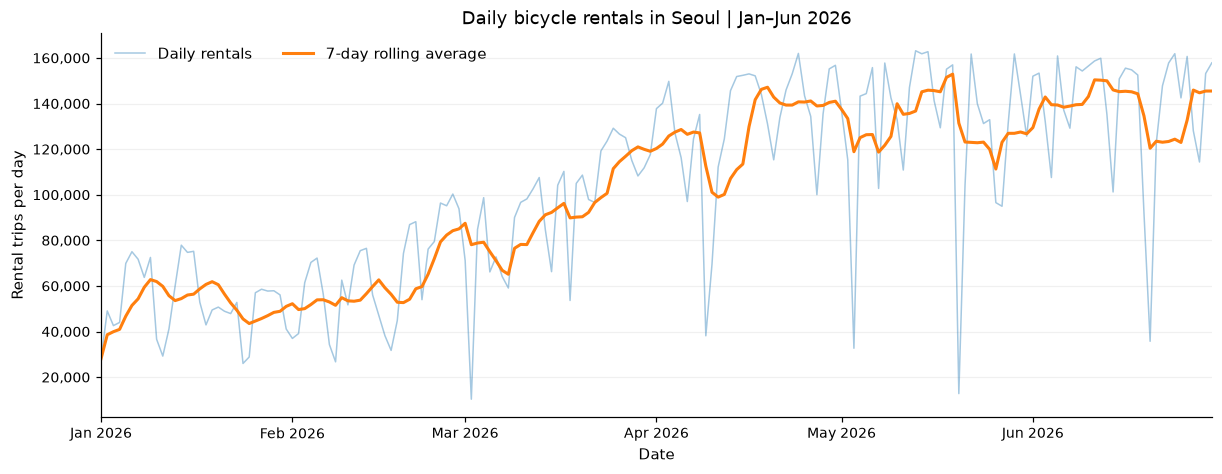

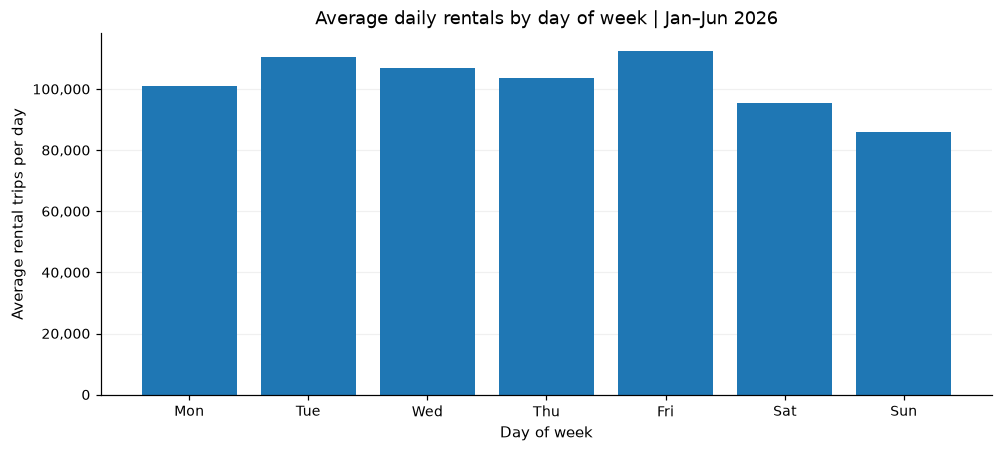

Total trip-level rentals in reporting period: 18,511,943.0
Mean daily rentals by month:


,count,mean,median
month,,,
2026-01,31,52922.0,52786.0
2026-02,28,64137.9,65864.0
2026-03,31,94374.5,98722.0
2026-04,30,131260.7,136612.5
2026-05,31,129976.5,139951.0
2026-06,30,139426.6,152270.0


Weekday versus weekend:


,count,mean,median
day_type,,,
Weekday,129,106944.5,107559.0
Weekend,52,90694.4,99577.5


In [27]:
# Temporal patterns: separate figures prevent label crowding.
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150,
    'font.size': 10, 'axes.titlesize': 12, 'axes.labelsize': 10,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.constrained_layout.use': True,
})
period = pd.date_range('2026-01-01', '2026-06-30', freq='D')
city_daily = daily_counts.groupby(level='date').sum()
city_daily.index = pd.to_datetime(city_daily.index)
city_daily = city_daily.reindex(period, fill_value=0).rename('rentals')
city_time = city_daily.to_frame()
city_time.index.name = 'date'
city_time['weekday'] = city_time.index.day_name()
city_time['day_type'] = np.where(city_time.index.dayofweek < 5, 'Weekday', 'Weekend')
city_time['month'] = city_time.index.to_period('M').astype(str)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(city_time.index, city_time['rentals'], lw=1, alpha=.4, label='Daily rentals')
ax.plot(city_time.index, city_time['rentals'].rolling(7, min_periods=1).mean(),
        lw=2, label='7-day rolling average')
ax.set(title='Daily bicycle rentals in Seoul | Jan–Jun 2026',
       xlabel='Date', ylabel='Rental trips per day')
ax.set_xlim(period.min(), period.max())  # Keep the axis within Jan–Jun; no July tick
ax.margins(x=0)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='y', alpha=.18)
ax.legend(frameon=False, loc='upper left', ncol=2)
plt.show()

weekday_means = city_time.groupby(city_time.index.dayofweek)['rentals'].mean().reindex(range(7))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(['Mon','Tue','Wed','Thu','Fri','Sat','Sun'], weekday_means)
ax.set(title='Average daily rentals by day of week | Jan–Jun 2026',
       xlabel='Day of week', ylabel='Average rental trips per day')
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='y', alpha=.18)
ax.set_axisbelow(True)
plt.show()

print('Total trip-level rentals in reporting period:', f'{city_daily.sum():,}')
print('Mean daily rentals by month:')
display(city_time.groupby('month')['rentals'].agg(['count','mean','median']).round(1))
print('Weekday versus weekend:')
display(city_time.groupby('day_type')['rentals'].agg(['count','mean','median']).round(1))

Weather days missing temperature: 0
Weather days missing precipitation: 0
Rental mean by rain-day category and day type (observational):


count      mean    median
day_type rain_day_1mm                           
Weekday  0.0             106  112532.4  121406.0
         1.0              23   81191.3   92193.0
Weekend  0.0              46   93005.6  103086.0
         1.0               6   72975.2   68924.5

Rental mean by subzero temperature and day type (observational):


count      mean    median
day_type below_zero                           
Weekday  0.0           105  118379.7  126617.0
         1.0            24   56915.2   57400.5
Weekend  0.0            44  101142.4  114736.0
         1.0             8   33230.5   31769.0

Spearman association between daily rentals and weather:


,rentals,avg_temp_c,precip_mm
rentals,1.000,0.808,-0.204
avg_temp_c,0.808,1.000,0.084
precip_mm,-0.204,0.084,1.000


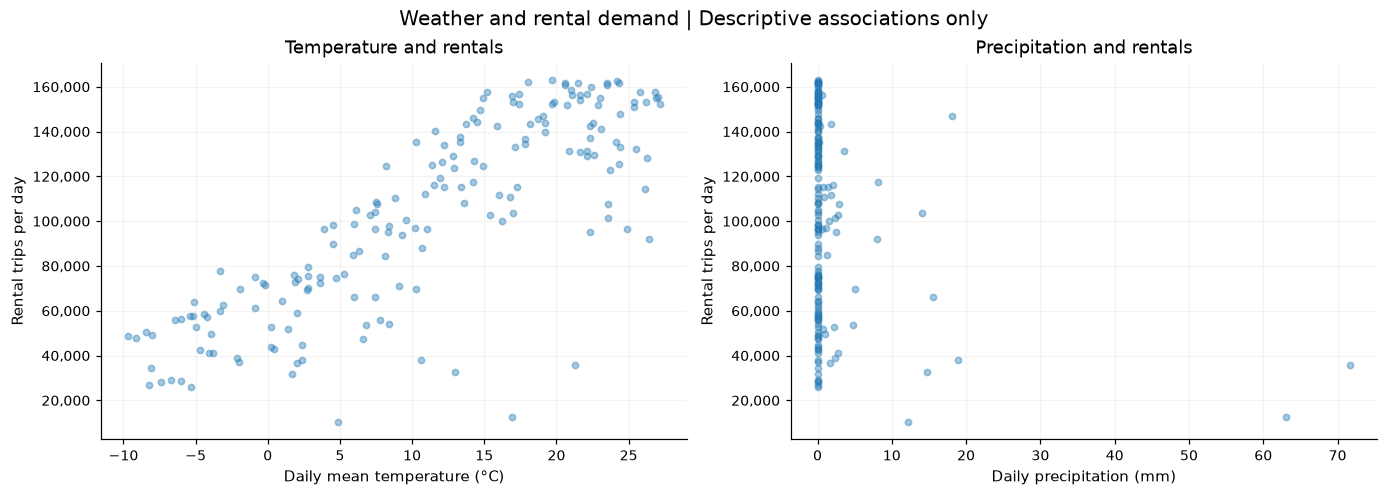

In [28]:
# Secondary descriptive weather context; these associations do not establish causality.
weather_daily = weather.drop_duplicates('date').set_index('date').reindex(period)
weather_daily.index.name = 'date'
wx = city_time[['rentals','day_type','month']].join(weather_daily[['avg_temp_c','precip_mm']], how='left')
wx['rain_day_1mm'] = np.where(wx['precip_mm'].isna(), np.nan, wx['precip_mm'] >= 1)
wx['below_zero'] = np.where(wx['avg_temp_c'].isna(), np.nan, wx['avg_temp_c'] < 0)
print('Weather days missing temperature:', wx['avg_temp_c'].isna().sum())
print('Weather days missing precipitation:', wx['precip_mm'].isna().sum())
print('Rental mean by rain-day category and day type (observational):')
display(wx.dropna(subset=['rain_day_1mm']).groupby(['day_type','rain_day_1mm'])['rentals'].agg(['count','mean','median']).round(1))
print('Rental mean by subzero temperature and day type (observational):')
display(wx.dropna(subset=['below_zero']).groupby(['day_type','below_zero'])['rentals'].agg(['count','mean','median']).round(1))
print('Spearman association between daily rentals and weather:')
display(wx[['rentals','avg_temp_c','precip_mm']].corr(method='spearman').round(3))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for ax, x_col, xlabel, title in [
    (axes[0], 'avg_temp_c', 'Daily mean temperature (°C)', 'Temperature and rentals'),
    (axes[1], 'precip_mm', 'Daily precipitation (mm)', 'Precipitation and rentals'),
]:
    ax.scatter(wx[x_col], wx['rentals'], s=17, alpha=.4)
    ax.set(title=title, xlabel=xlabel, ylabel='Rental trips per day')
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
    ax.grid(alpha=.15)
fig.suptitle('Weather and rental demand | Descriptive associations only', fontsize=13)
plt.show()

Stations with at least 50 rentals: 2,777


,count,mean,std,min,10%,25%,50%,75%,90%,max
total_rentals,2777.0,6666.130,6074.214,166.000,1442.200,2739.000,4948.000,8600.000,13977.000,72001.000
am_peak_share,2777.0,0.202,0.094,0.011,0.086,0.133,0.191,0.265,0.332,0.591
pm_peak_share,2777.0,0.246,0.081,0.067,0.159,0.191,0.232,0.288,0.343,0.643
night_share,2777.0,0.114,0.052,0.002,0.053,0.077,0.108,0.144,0.182,0.385
weekend_share,2777.0,0.254,0.059,0.000,0.182,0.225,0.257,0.286,0.313,0.568
round_trip_share,2777.0,0.095,0.043,0.020,0.055,0.069,0.087,0.113,0.141,0.930
am_net_flow,2777.0,-0.115,0.417,-0.959,-0.659,-0.437,-0.136,0.171,0.443,0.948
pm_net_flow,2777.0,-0.012,0.265,-0.955,-0.378,-0.154,0.024,0.169,0.296,0.705


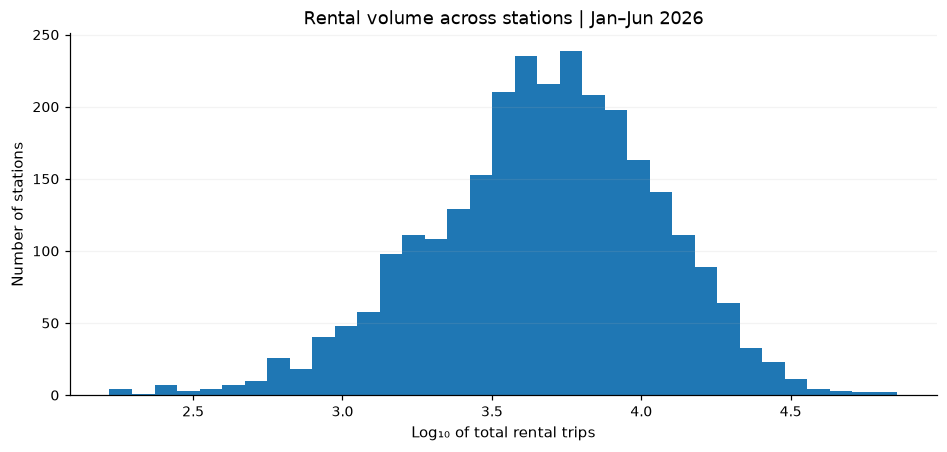

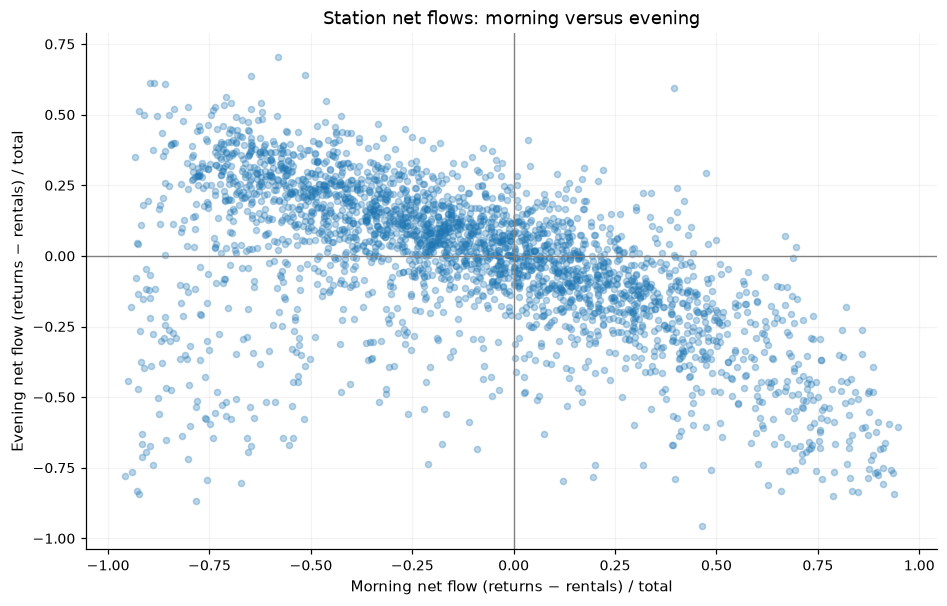

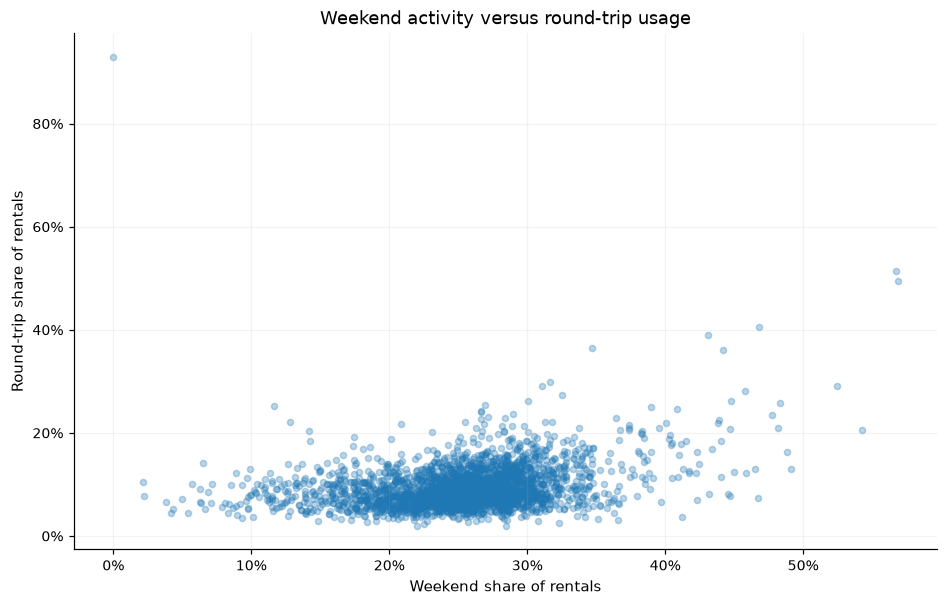

Highest volume stations (descriptive, not PCA scores):


,station_name_en,total_rentals,weekend_share,am_net_flow,pm_net_flow
station_id,,,,,
ST-2031,Magoknaruyeok 2Beon Chulgu,72001,0.205817,-0.039356,-0.034624
ST-3388,Hangangbeoseu Mangwon Seonchakjang,64749,0.447358,0.050078,0.018762
ST-891,Rotdewoldeutawo(Jamsilyeok2Beonchulgu Jjok),54503,0.260371,0.393792,-0.288165
ST-2045,Magoknaruyeok 3Beon Chulgu,52801,0.172743,-0.076618,0.122298
ST-1718,Magoknaruyeok 5Beonchulgu Dwipyeon,49969,0.148052,-0.033141,-0.058753
ST-3402,Hangangbeoseu Yeouido Seonchakjang,49172,0.431384,-0.041142,-0.089275
ST-1065,"Balsanyeok 1Beon, 9Beon Ingeun Daeyeoso",42823,0.233940,-0.086086,0.169013
ST-1720,Olrimpikgongwonyeok 3Beonchulgu,37783,0.326972,0.123044,-0.070650
ST-3390,Hangangbeoseu Ttukseom Seonchakjang,37407,0.441655,0.180290,-0.030679


In [29]:
# Station differences: use individual figures rather than a cramped three-panel row.
station_metrics = ['total_rentals','am_peak_share','pm_peak_share','night_share',
                   'weekend_share','round_trip_share','am_net_flow','pm_net_flow']
station_view = station_features.loc[station_features['total_rentals'] >= 50, station_metrics].copy()
print(f'Stations with at least 50 rentals: {len(station_view):,}')
display(station_view.describe(percentiles=[.1,.25,.5,.75,.9]).T.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hist(np.log10(station_view['total_rentals']), bins=35)
ax.set(title='Rental volume across stations | Jan–Jun 2026',
       xlabel='Log₁₀ of total rental trips', ylabel='Number of stations')
ax.grid(axis='y', alpha=.15)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.scatter(station_view['am_net_flow'], station_view['pm_net_flow'], alpha=.3, s=16)
ax.axhline(0, color='gray', lw=.9)
ax.axvline(0, color='gray', lw=.9)
ax.set(title='Station net flows: morning versus evening',
       xlabel='Morning net flow (returns − rentals) / total',
       ylabel='Evening net flow (returns − rentals) / total')
ax.grid(alpha=.15)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.scatter(station_view['weekend_share'], station_view['round_trip_share'], alpha=.3, s=16)
ax.set(title='Weekend activity versus round-trip usage',
       xlabel='Weekend share of rentals', ylabel='Round-trip share of rentals')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.grid(alpha=.15)
plt.show()

print('Highest volume stations (descriptive, not PCA scores):')
display(station_features[['station_name_en','total_rentals','weekend_share','am_net_flow','pm_net_flow']].nlargest(10,'total_rentals'))

In [30]:
# Cross-source reconciliation: compare reported counts without conflating definitions.
trip_total = int(city_daily.sum())
print(f"Trip-level rentals (Jan–Jun 2026): {trip_total:,}")
summary = df.copy()
summary['rental_date'] = pd.to_datetime(summary['rental_date'], errors='coerce')
summary['rental_count'] = pd.to_numeric(summary['rental_count'], errors='coerce')
print('Daily-summary rows:', len(summary))
print('Null / invalid dates:', summary['rental_date'].isna().sum())
print('Null / invalid counts:', summary['rental_count'].isna().sum())
print('Duplicate dates:', summary['rental_date'].dropna().duplicated().sum())
print('Date range:', summary['rental_date'].min(), 'to', summary['rental_date'].max())
window = summary.loc[summary['rental_date'].between(period.min(), period.max())]
summary_total = window['rental_count'].sum(min_count=1)
print(f'Daily summary total (same date window): {summary_total:,.0f}')
if pd.notna(summary_total):
    diff = trip_total - summary_total
    print(f'Trip minus daily summary: {diff:,.0f} ({100 * diff / trip_total:.2f}% of trip-level total)')
print('Interpretation: The sources differ, but the reason is not established. Do not treat this as lost records.')

Trip-level rentals (Jan–Jun 2026): 18,511,943
Daily-summary rows: 181
Null / invalid dates: 0
Null / invalid counts: 0
Duplicate dates: 0
Date range: 2026-01-01 00:00:00 to 2026-06-30 00:00:00
Daily summary total (same date window): 17,978,991
Trip minus daily summary: 532,952 (2.88% of trip-level total)
Interpretation: The sources differ, but the reason is not established. Do not treat this as lost records.


## Interpretation of the descriptive results

### Temporal variation (primary finding)

The trip-level records contain **18,511,943 rentals** for January–June 2026. Mean daily rentals rose from approximately **52,922 in January** to **139,427 in June**. Weekdays averaged **106,945 rentals per day**, versus **90,694 on weekends**. The comparisons are descriptive and are not adjusted for the number of active stations.

### Station differences (primary finding)

In the 2,777-station PCA sample, the median station recorded **4,948 rentals** over the study period (90th percentile **13,977**; highest **72,001**). Median station-level weekend, night and round-trip shares were **25.7%**, **10.8%**, and **8.7%** respectively. Morning and evening net-flow indicators show substantial variation in when stations accumulate or lose bicycles; this is a station-level behavioral pattern, not a direct inventory or capacity measurement.

### Weather conditions (limited descriptive context)

Across the six-month sample, daily rentals are generally lower on days meeting the chosen rain-day criterion (≥1 mm) and on subzero days. The unadjusted Spearman association between temperature and rental count is **+0.808**, but the same period also transitions from winter into summer. Thus, these figures are reported as descriptive co-variation only; **no independent weather effect can be inferred**. Weather remains outside PCA.

### Cross-source counts

The trip-level total is internally consistent with the station aggregation. The executed reconciliation reports **17,978,991 rentals** in the separate daily-summary file, compared with **18,511,943 trip-level rentals** over the same January–June dates: a difference of **532,952 (2.88% of the trip-level total)**. The saved validation reports 181 unique daily-summary dates, no missing dates or counts, and no duplicate dates. The difference is **between two source datasets**; the saved outputs do not identify individual rental records responsible for it. The diagnostic above compares dates and plausible record categories without altering the PCA input. A numerical difference alone does **not** establish a cleaning error or prove a particular exclusion rule.

# Principal Component Analysis (PCA)

PCA is the **primary descriptive dimensionality-reduction method** in this notebook. It summarizes correlated usage measurements into continuous axes of station variation. It does not establish causal effects, discrete station groups or a predictive model. Input variables are standardized before PCA; **the original PCA scores are not subsequently forced to unit variance or whitened**.

In [31]:
## Setup
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings(action = 'ignore')

## 1. Input Variables and Preprocessing

### Variables

We start with 11 candidate station-level variables that describe **how** a station is used. Spatial context (subway distance, bicycle paths and district) is not included in this station-behavior PCA. These features can be investigated separately in future work.

| Group | Variables |
|---|---|
| Time of day | `am_peak_share`, `pm_peak_share`, `night_share`, `weekend_share` |
| Trip type | `median_duration_min`, `median_distance_m`, `round_trip_share` |
| Bike flow | `am_net_flow`, `pm_net_flow` |
| Station size | `log_total_rentals` |
| Rider mix | `non_member_share` |

### Why weather is excluded from the PCA

Weather was considered in an earlier exploratory version but excluded from the final station-level PCA. With only January–June data, weather, season, holidays and changes in demand are intertwined. Citywide daily observations are also too coarse to characterize weather exposure at each station. In the earlier exploratory run, `rain_ratio` largely formed its own component rather than adding a clear station-behavior dimension. **We therefore retain the original ten behavior-only PCA variables and the original unwhitened PCA score scale.** Weather is presented as a limited observational comparison only; formal weather-response modeling is outside the current scope.

### Preprocessing steps

1. **Low-volume stations:** stations with fewer than 50 rentals in six months are removed (30 stations). Their shares are based on too few trips (many are exactly 0 or 1) and would act as outliers. This leaves **2,777 stations**.
2. **Missing values:** after that filter, none of the 11 variables has missing values, so no imputation is needed. (Before the filter, a few stations with no weekday rentals had undefined peak shares; the filter removes them.)
3. **Redundant variables:** the correlation matrix below shows `median_duration_min` and `median_distance_m` are almost the same measurement (r = 0.91). Keeping both would give "trip length" double weight in PCA, so `median_distance_m` is dropped. No other pair exceeds |r| = 0.74. This leaves **10 variables**.
4. **Outliers:** several variables are strongly right-skewed because of a few extreme stations (e.g. `round_trip_share` and `non_member_share` both have a skew of about 4.4). Each variable is clipped at its 1st and 99th percentiles (winsorizing) so a handful of stations cannot dominate a component.
5. **Measurement scale:** the variables are in different units (minutes, proportions from 0-1, net flow from −1 to 1, log counts). PCA is driven by variance, so unscaled variables with larger ranges would dominate. All variables are standardized with `StandardScaler` (mean 0, standard deviation 1).

In [32]:
## Candidate variables and low-volume / missing-value filtering
CANDIDATE_VARS = ["am_peak_share", "pm_peak_share", "night_share", "weekend_share",
                  "median_duration_min", "median_distance_m", "round_trip_share",
                  "am_net_flow", "pm_net_flow", "log_total_rentals",
                  "non_member_share"]   # cold_ratio / rain_ratio excluded (see note above)

MIN_RENTALS = 50
active = station_features[station_features["total_rentals"] >= MIN_RENTALS]
print(f"Stations: {len(station_features):,} total, {len(active):,} with >= {MIN_RENTALS} rentals")
print("Missing values after the volume filter:")
print(active[CANDIDATE_VARS].isnull().sum()[lambda s: s > 0])

pca_input = active.dropna(subset=CANDIDATE_VARS)
print(f"Stations used for PCA: {len(pca_input):,}")

Stations: 2,807 total, 2,777 with >= 50 rentals
Missing values after the volume filter:
Series([], dtype: int64)
Stations used for PCA: 2,777


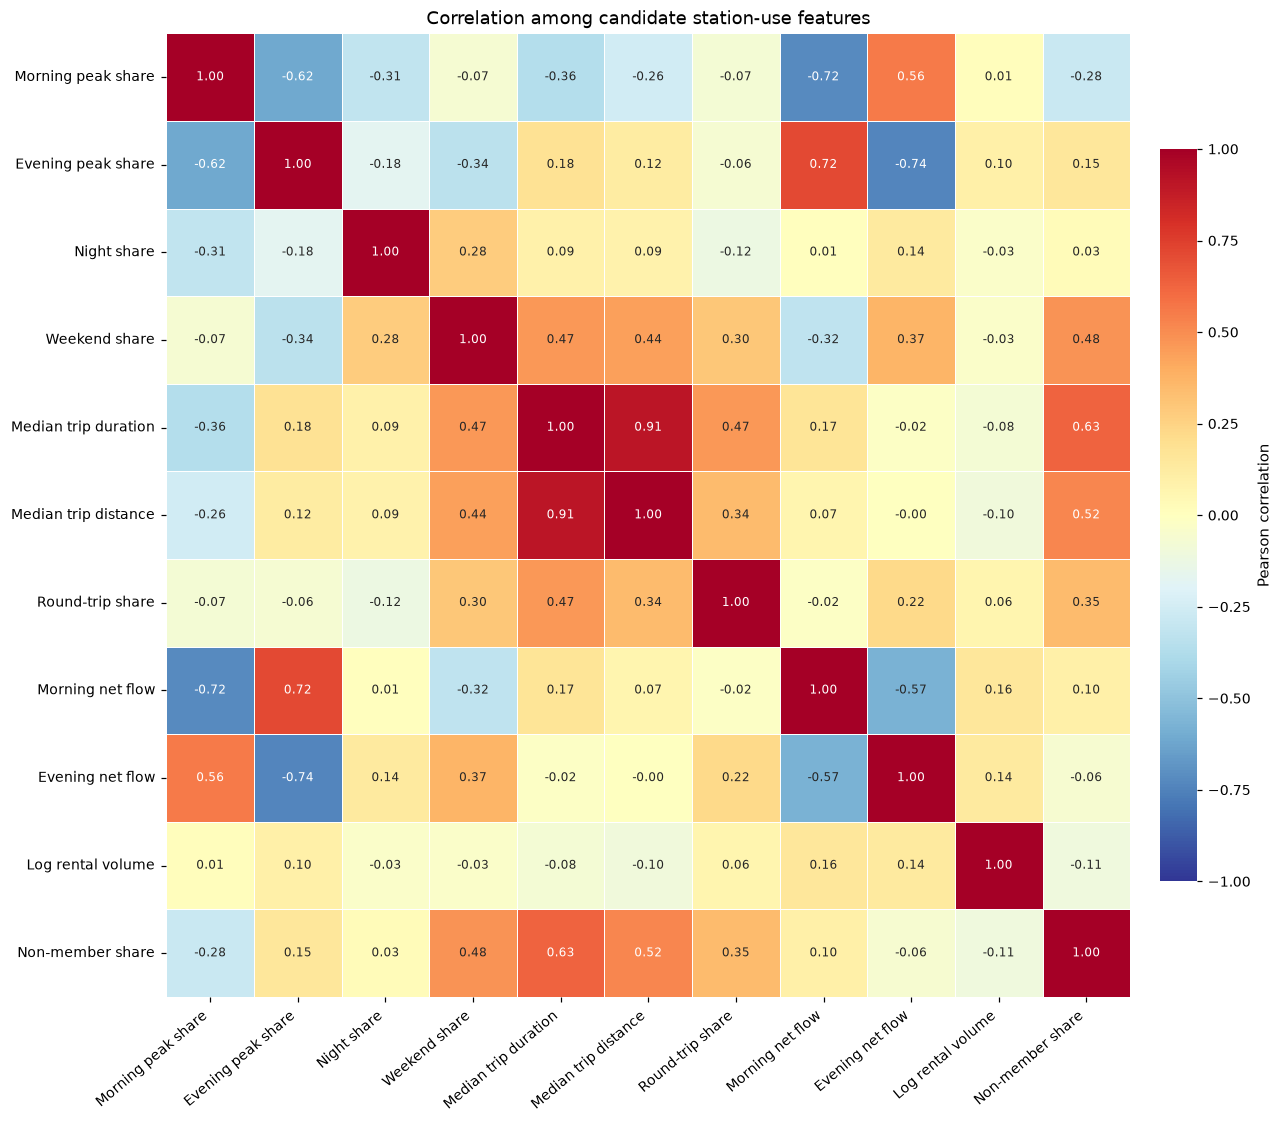

In [33]:
# Candidate-feature correlations with short, human-readable axis labels.
# Calculations and original feature names remain unchanged.
FEATURE_LABELS = {
    'am_peak_share': 'Morning peak share',
    'pm_peak_share': 'Evening peak share',
    'night_share': 'Night share',
    'weekend_share': 'Weekend share',
    'median_duration_min': 'Median trip duration',
    'median_distance_m': 'Median trip distance',
    'round_trip_share': 'Round-trip share',
    'non_member_share': 'Non-member share',
    'am_net_flow': 'Morning net flow',
    'pm_net_flow': 'Evening net flow',
    'log_total_rentals': 'Log rental volume',
}
cor = pca_input[CANDIDATE_VARS].corr()
cor_display = cor.rename(index=FEATURE_LABELS, columns=FEATURE_LABELS)
fig, ax = plt.subplots(figsize=(12.4, 10.1))
sns.heatmap(cor_display, annot=True, fmt='.2f', cmap='RdYlBu_r',
            vmin=-1, vmax=1, center=0, square=True,
            linewidths=.4, linecolor='white',
            annot_kws={'size': 8},
            cbar_kws={'label': 'Pearson correlation', 'shrink': .76, 'pad': .025}, ax=ax)
ax.set(title='Correlation among candidate station-use features',
       xlabel='', ylabel='')
ax.tick_params(axis='x', rotation=40, labelsize=9, pad=4)
ax.tick_params(axis='y', rotation=0, labelsize=9, pad=4)
for tick in ax.get_xticklabels():
    tick.set_ha('right')
plt.show()

In [34]:
## Drop the redundant variable, clip outliers, and standardize
PCA_VARS = [v for v in CANDIDATE_VARS if v != "median_distance_m"]   # r = 0.91 with median_duration_min

station_raw = pca_input[PCA_VARS]
station_clipped = station_raw.clip(station_raw.quantile(0.01), station_raw.quantile(0.99), axis = 1)

print("Skewness before and after clipping:")
print(pd.DataFrame({"before": station_raw.skew(), "after": station_clipped.skew()}).round(2))

station_st = StandardScaler().fit_transform(station_clipped)
station_st = pd.DataFrame(station_st, columns = PCA_VARS, index = station_clipped.index)
station_st.head(10)

Skewness before and after clipping:
                     before  after
am_peak_share          0.51   0.42
pm_peak_share          1.25   1.09
night_share            0.87   0.66
weekend_share          0.02  -0.14
median_duration_min    2.06   1.72
round_trip_share       4.48   1.12
am_net_flow            0.24   0.23
pm_net_flow           -0.67  -0.67
log_total_rentals     -0.37  -0.30
non_member_share       4.41   2.52


,am_peak_share,pm_peak_share,night_share,weekend_share,median_duration_min,round_trip_share,am_net_flow,pm_net_flow,log_total_rentals,non_member_share
station_id,,,,,,,,,,
ST-2031,0.673314,0.736885,-0.662395,-0.858517,-1.063632,-1.239064,0.181533,-0.084415,2.112184,-0.713925
ST-3388,-1.718053,0.469221,0.258303,3.023724,4.187700,3.547270,0.396639,0.118738,2.112184,5.113428
ST-891,-0.510272,1.976274,-1.040339,0.115088,-0.197075,-0.913910,1.223341,-1.049226,2.112184,0.838854
ST-2045,0.439958,0.857043,0.512584,-1.448766,-1.063632,-1.490915,0.091909,0.512731,2.112184,-0.555580
ST-1718,2.347323,0.280277,-1.422514,-1.889416,-1.280271,-1.599594,0.196480,-0.176231,2.112184,-0.858045
ST-3402,-1.817409,0.951363,0.415836,3.023724,4.187700,3.547270,0.177237,-0.292379,2.112184,5.113428
ST-1065,-0.474345,0.132957,1.559213,-0.356618,-0.846993,-1.327862,0.069138,0.690498,2.112184,-0.500441
ST-1720,-0.109022,0.555842,-0.607633,1.303690,0.019564,0.886247,0.572137,-0.221504,2.112184,1.337234
ST-3390,-1.813314,0.871597,0.608584,3.023724,4.187700,3.547270,0.709825,-0.069400,2.112184,5.113428


## 2. Component Selection

In [35]:
pca = PCA(random_state = 2000, n_components = None)
pca.fit(station_st)

## Variance (eigenvalues) and explained variance ratio of each component
pc_list = ["PC" + str(i) for i in range(1, len(PCA_VARS) + 1)]
variance_df = pd.DataFrame({
    "eigenvalue": pca.explained_variance_,
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_ratio": np.cumsum(pca.explained_variance_ratio_),
}, index = pc_list)
variance_df.round(3)

,eigenvalue,explained_variance_ratio,cumulative_ratio
PC1,3.178,0.318,0.318
PC2,2.527,0.253,0.570
PC3,1.273,0.127,0.698
PC4,1.127,0.113,0.810
PC5,0.616,0.062,0.872
PC6,0.371,0.037,0.909
PC7,0.316,0.032,0.941
PC8,0.282,0.028,0.969
PC9,0.185,0.018,0.987
PC10,0.128,0.013,1.000


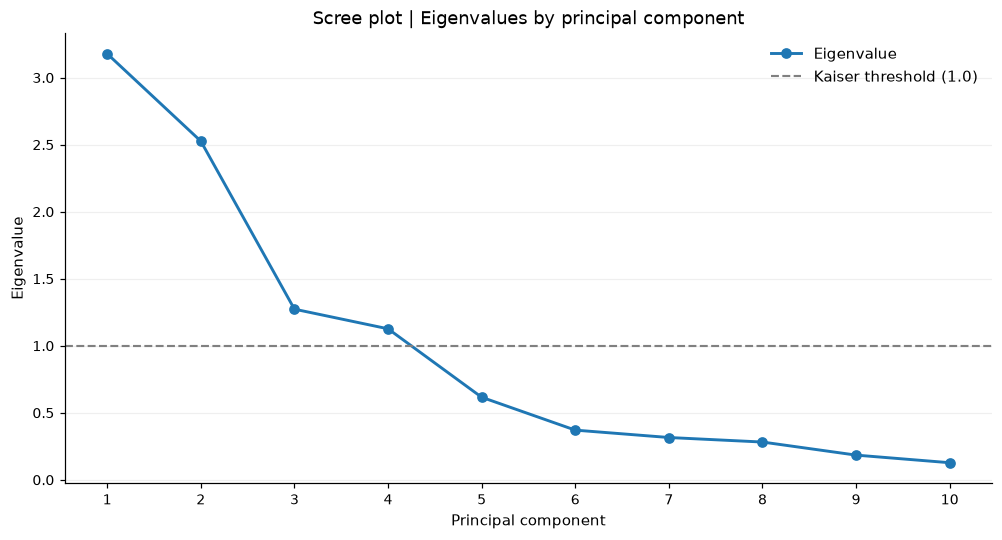

In [36]:
# Scree plot: individual PCA eigenvalues and the Kaiser threshold.
x_axis = np.arange(1, len(PCA_VARS) + 1)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, pca.explained_variance_, marker='o', lw=1.9, label='Eigenvalue')
ax.axhline(1, color='gray', linestyle='--', lw=1.4, label='Kaiser threshold (1.0)')
ax.set(xticks=x_axis, xlabel='Principal component', ylabel='Eigenvalue',
       title='Scree plot | Eigenvalues by principal component')
ax.grid(axis='y', alpha=.2)
ax.legend(frameon=False, loc='upper right')
plt.show()

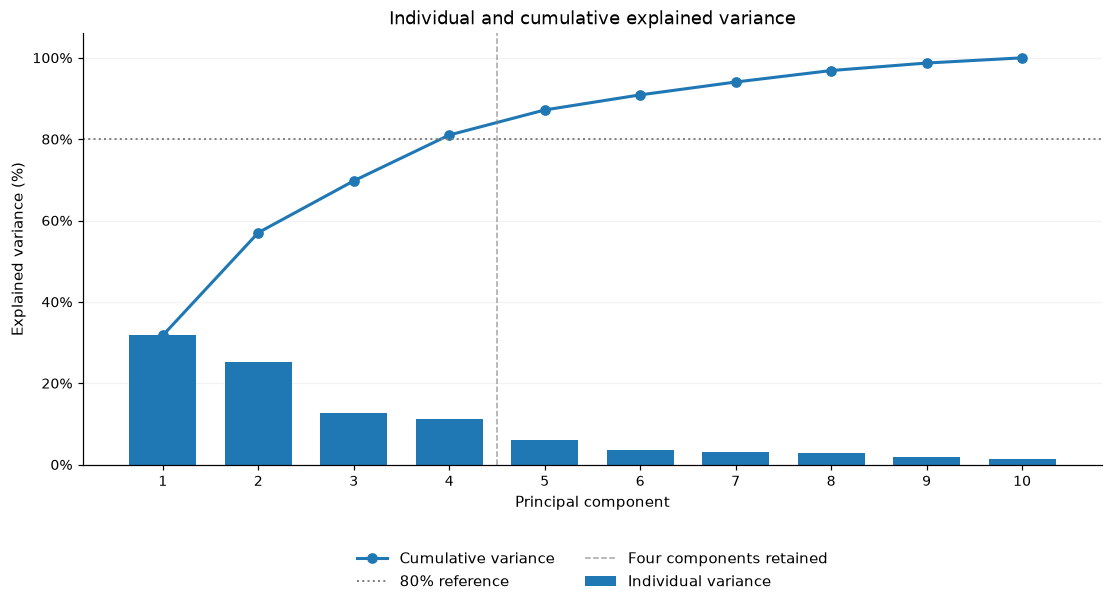

In [37]:
# Explained variance: separate bars and cumulative line, with an unobstructed legend.
exp_variance_ratio = pca.explained_variance_ratio_

def explained_variance_ratio_plot(exp_variance_ratio):
    x_axis = np.arange(1, len(exp_variance_ratio) + 1)
    fig, ax = plt.subplots(figsize=(10, 5.4))
    ax.bar(x_axis, exp_variance_ratio * 100, width=.7, label='Individual variance')
    ax.plot(x_axis, np.cumsum(exp_variance_ratio) * 100,
            marker='o', lw=2, label='Cumulative variance')
    ax.axhline(80, color='gray', linestyle=':', lw=1.3, label='80% reference')
    ax.axvline(4.5, color='gray', linestyle='--', lw=1, alpha=.7,
               label='Four components retained')
    ax.set(xticks=x_axis, ylim=(0, 106), xlabel='Principal component',
           ylabel='Explained variance (%)',
           title='Individual and cumulative explained variance')
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100, decimals=0))
    ax.grid(axis='y', alpha=.15)
    ax.set_axisbelow(True)
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.17),
              ncol=2, frameon=False)
    plt.show()

explained_variance_ratio_plot(exp_variance_ratio)

### Explained variance and component retention

The executed PCA output gives the following explained variance ratios:

| Component | Eigenvalue | Explained variance | Cumulative variance |
|---|---:|---:|---:|
| PC1 | 3.178 | 31.8% | 31.8% |
| PC2 | 2.527 | 25.3% | 57.0% |
| PC3 | 1.273 | 12.7% | 69.8% |
| PC4 | 1.127 | 11.3% | 81.0% |
| PC5 | 0.616 | 6.2% | 87.2% |

Four components satisfy the Kaiser eigenvalue-greater-than-one criterion and retain approximately **81.0%** of standardized-feature variance. These four components provide a compact, interpretable summary of the ten PCA input variables. The Kaiser criterion and the 80% threshold are heuristics rather than definitive statistical tests.

## 3. Component Interpretation

The sign of a principal component is arbitrary (PCA can return a component or its mirror image). To make the interpretation stable, each component is oriented so that a chosen reference variable has a positive loading: `pm_peak_share` for PC1, `weekend_share` for PC2, `night_share` for PC3, `log_total_rentals` for PC4 and `round_trip_share` for PC5. Flipping a sign does not change the variance explained or the analysis.

In [38]:
## Orient the signs of the first five components so they read the same way every run
ANCHORS = ["pm_peak_share", "weekend_share", "night_share", "log_total_rentals", "round_trip_share"]
for i, var in enumerate(ANCHORS):
    if pca.components_[i, PCA_VARS.index(var)] < 0:
        pca.components_[i] *= -1

N_KEEP = 4

## Loadings (eigenvectors): one column per component
loadings_df = pd.DataFrame(pca.components_.T, columns = pc_list, index = PCA_VARS)
loadings_df.index.name = "variable"
loadings_df.iloc[:, :N_KEEP + 1].round(2)

,PC1,PC2,PC3,PC4,PC5
variable,,,,,
am_peak_share,-0.47,-0.17,-0.26,-0.14,-0.16
pm_peak_share,0.50,-0.08,-0.15,-0.00,-0.13
night_share,-0.01,0.17,0.75,0.32,0.21
weekend_share,-0.16,0.50,0.17,0.05,-0.32
median_duration_min,0.17,0.51,-0.13,-0.08,0.06
round_trip_share,-0.03,0.39,-0.47,0.14,0.62
am_net_flow,0.49,-0.05,-0.02,0.22,0.18
pm_net_flow,-0.46,0.17,-0.03,0.26,0.13
log_total_rentals,0.01,-0.06,-0.28,0.83,-0.40


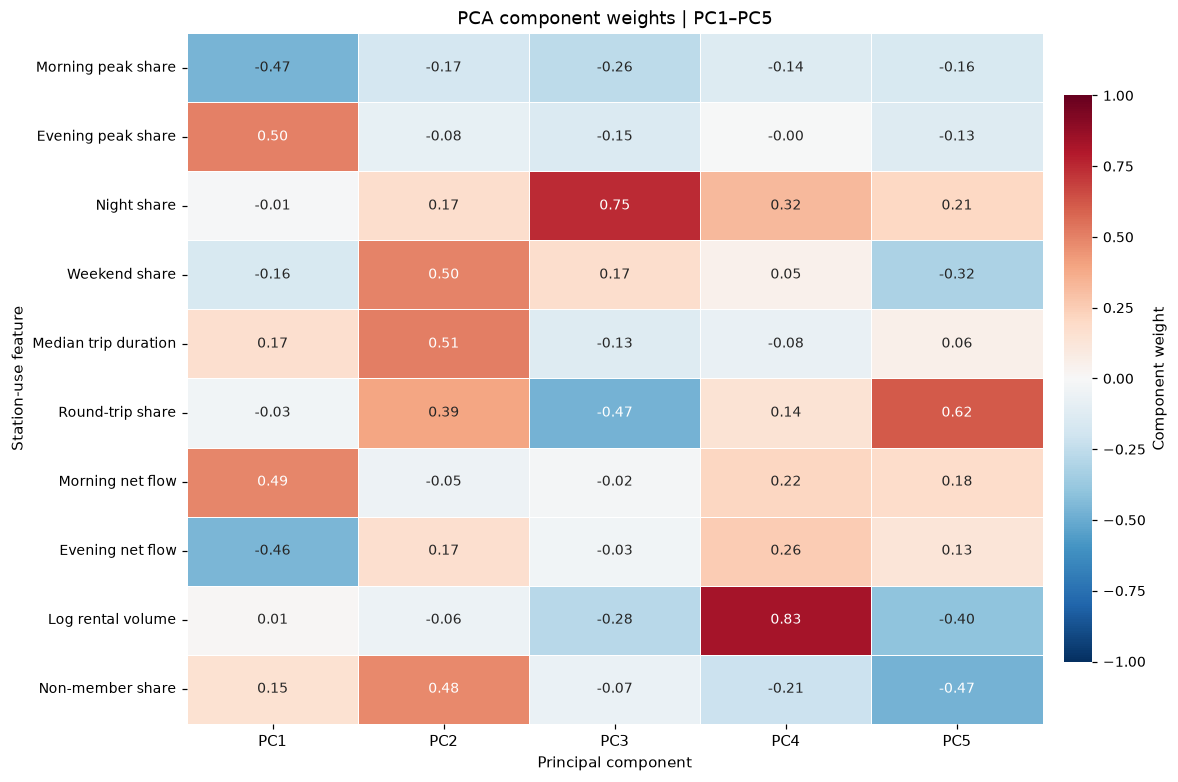

In [39]:
# PCA component weights: accessible variable labels and unobstructed colorbar.
weights_display = loadings_df.iloc[:, :N_KEEP + 1].rename(index=FEATURE_LABELS)
fig, ax = plt.subplots(figsize=(10.6, 7.0))
sns.heatmap(weights_display, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=.5,
            linecolor='white', cbar_kws={'label': 'Component weight', 'shrink': .82, 'pad': .025},
            annot_kws={'size': 9}, ax=ax)
ax.set(title='PCA component weights | PC1–PC5',
       xlabel='Principal component', ylabel='Station-use feature')
ax.tick_params(axis='x', rotation=0, labelsize=10)
ax.tick_params(axis='y', rotation=0, labelsize=9)
plt.show()

In [40]:
## Strongest contributors to each retained component (|loading| >= 0.3)
for pc in pc_list[:N_KEEP]:
    top = loadings_df[pc][loadings_df[pc].abs() >= 0.3].sort_values(key = abs, ascending = False)
    print(f"{pc} ({pca.explained_variance_ratio_[pc_list.index(pc)]*100:.1f}%):",
          ", ".join(f"{v} ({w:+.2f})" for v, w in top.items()))

PC1 (31.8%): pm_peak_share (+0.50), am_net_flow (+0.49), am_peak_share (-0.47), pm_net_flow (-0.46)
PC2 (25.3%): median_duration_min (+0.51), weekend_share (+0.50), non_member_share (+0.48), round_trip_share (+0.39)
PC3 (12.7%): night_share (+0.75), round_trip_share (-0.47)
PC4 (11.3%): log_total_rentals (+0.83), night_share (+0.32)


In [41]:
## Projected data (scores) for each station
scores_df = pd.DataFrame(pca.transform(station_st), columns = pc_list, index = station_st.index)
scores_df.insert(0, "station_name_en", pca_input["station_name_en"])
scores_df.insert(1, "total_rentals", pca_input["total_rentals"])

## Stations with the highest and lowest scores on each retained component (busy stations only, for readability)
busy = scores_df[scores_df["total_rentals"] >= 2000]
for pc in pc_list[:N_KEEP]:
    print(f"\n{pc} highest:", ", ".join(busy.nlargest(4, pc)["station_name_en"].fillna("(no name)")))
    print(f"{pc} lowest: ", ", ".join(busy.nsmallest(4, pc)["station_name_en"].fillna("(no name)")))


PC1 highest: Hanguksaneopeunhaeng, Woldeumereudiang Bencheosenteo 2Cha, Geumyunggamdokwon Ap, Byeoksan Dijiteolbaelri 5Cha
PC1 lowest:  Godeokraemianhilseuteiteu Apateu 211Dong, Samilsuyeongjang Ap, Cheongnyeonjutaek Doksandongjeom, Gongreungpungrimapateu 108Dong

PC2 highest: Sinbanpoyeok 2Beonchulgu Ap, Hangangbeoseu Mangwon Seonchakjang, Hangangbeoseu Ttukseom Seonchakjang, Hangangbeoseu Yeouido Seonchakjang
PC2 lowest:  Lgsaieonseupakeu W4Dong, Rotde R&D Senteo, Lgsaieonseupakeu E14Dong, Koorongone&Onlytawo

PC3 highest: Itaewonyeok 3Beon Chulgu, Songpapakeudeil 1Danji 115Dong Geonneopyeon, Sinnaeyeoksitipeuradium Ap, Samgakjiyeok 3Beonchulgu
PC3 lowest:  Doksanbodoyukgyo Ap Jajeongeo Bogwanso, Woldeukeopgongwon, Jongro6Gayeok Beoseujeongryujang(Dongdaemun Banghyang), Saneopeunhaeng Ap

PC4 highest: Bongrimgyo Gyotongseom, Bangisamgeori, Omokgyoyeok 3Beonchulgu, Sinrimyeok 8Beonchulgu
PC4 lowest:  Cheonwangipenhauseu3Danji Ap, Seobinggodong Geumhomaensyeon Ap, Wolgyejunghakgyo, Gu

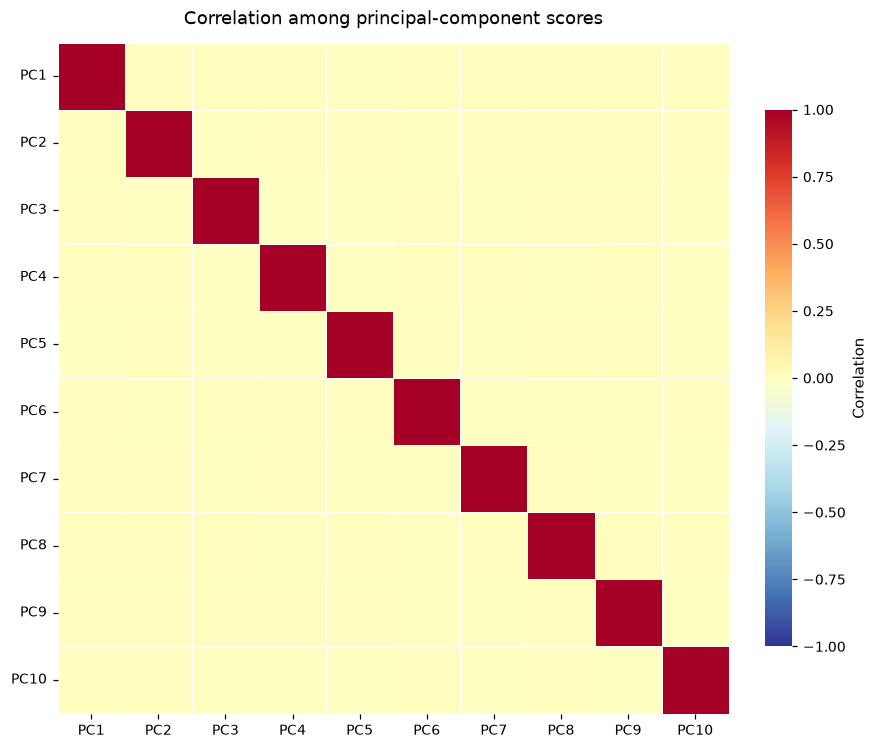

In [42]:
# PCA scores should be uncorrelated; preserve the natural PC1...PC10 order.
score_corr = scores_df[pc_list].corr()
fig, ax = plt.subplots(figsize=(8, 6.7))
sns.heatmap(score_corr, cmap='RdYlBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=.4, linecolor='white',
            cbar_kws={'label': 'Correlation', 'shrink': .8}, ax=ax)
ax.set_title('Correlation among principal-component scores', pad=12)
ax.tick_params(axis='x', rotation=0)
ax.tick_params(axis='y', rotation=0)
plt.show()

### Principal-component interpretation

Based on the executed component-weight table (orientation fixed by the code):

- **PC1 — Commuting-direction variation (31.8%).** Positive weights for `pm_peak_share` (+0.50) and `am_net_flow` (+0.49) contrast with negative weights for `am_peak_share` (−0.47) and `pm_net_flow` (−0.46). Positive-score stations are associated with morning bicycle inflow and evening outflow (work-destination-like behavior); negative-score stations exhibit the reverse (residential-origin-like behavior).
- **PC2 — Leisure-oriented versus routine usage (25.3%).** Larger positive weights for median duration (+0.51), weekend share (+0.50), non-member share (+0.48), and round-trip share (+0.39) characterize longer, weekend-oriented, casual-use patterns. The highest-score examples include stations near the Han River.
- **PC3 — Night-use variation (12.7%).** Dominated by night share (+0.75), contrasted with round-trip share (−0.47). This dimension separates relatively night-oriented use from round-trip-oriented activity.
- **PC4 — Overall rental activity (11.3%).** Primarily associated with log total rentals (+0.83), with a smaller contribution from night share (+0.32). High PC4 scores represent higher-activity stations after accounting for the other dimensions.

These are interpretations of **continuous axes**, not confirmed station categories. Component signs can be reversed without changing the PCA solution. The reported coefficients are PCA component weights (`components_`), sometimes called loadings informally, rather than variable–component correlation loadings.

## PCA biplot

This standard biplot shows station scores as points and the directions of the ten usage variables as arrows. Arrows are uniformly scaled for display; the station scores and PCA results are unchanged. The first two components together explain approximately 57.1% of standardized station-use variance. The arrow lengths are not expressed in station-score units.

In [ ]:
# Standard PCA biplot: station scores and feature vectors on one chart.
# The same arrow multiplier is used for every feature; PCA scores are unchanged.
import numpy as np
import matplotlib.pyplot as plt

points = scores_df[["PC1", "PC2"]].to_numpy(dtype=float)
weights = pca.components_[:2, :].T
assert weights.shape == (len(PCA_VARS), 2)

short_labels = {
    "am_peak_share": "AM peak",
    "pm_peak_share": "PM peak",
    "night_share": "Night",
    "weekend_share": "Weekend",
    "median_duration_min": "Duration",
    "round_trip_share": "Round trips",
    "am_net_flow": "AM net flow",
    "pm_net_flow": "PM net flow",
    "log_total_rentals": "Rental volume",
    "non_member_share": "Nonmembers",
}

# A single display scale brings the loadings into the score coordinate system.
# The factor has no effect on the underlying scores, directions, or PCA model.
central_limits = np.percentile(points, [5, 95], axis=0)
central_width = np.diff(central_limits, axis=0).ravel()
vector_max = np.maximum(np.max(np.abs(weights), axis=0), 1e-8)
arrow_scale = 0.36 * np.min(central_width / vector_max)
vectors = weights * arrow_scale

fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(points[:, 0], points[:, 1], s=10, alpha=0.25,
           color="steelblue", edgecolors="none", rasterized=True)
ax.axhline(0, color="0.6", lw=0.8)
ax.axvline(0, color="0.6", lw=0.8)

# Put short labels beside the arrow tips; spread only labels that would collide.
# This keeps one conventional, uncluttered biplot without a numbered key.
labels = [short_labels.get(f, f.replace("_", " ")) for f in PCA_VARS]
ends = vectors.copy()
label_y = ends[:, 1].copy()
for side in (-1, 1):
    selected = [i for i, xy in enumerate(ends) if (1 if xy[0] >= 0 else -1) == side]
    selected.sort(key=lambda i: ends[i, 1])
    min_separation = max(0.23, 0.042 * np.ptp(points[:, 1]))
    for j in range(1, len(selected)):
        prev, cur = selected[j-1], selected[j]
        label_y[cur] = max(label_y[cur], label_y[prev] + min_separation)
    if selected:
        offset = (label_y[selected[-1]] - ends[selected[-1], 1] +
                  label_y[selected[0]] - ends[selected[0], 1]) / 2
        label_y[selected] -= offset

for i, (x, y) in enumerate(ends):
    ax.annotate("", xy=(x, y), xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "color": "firebrick", "lw": 1.5})
    side = 1 if x >= 0 else -1
    x_text = x + side * 0.11
    ax.annotate(labels[i], xy=(x, y), xytext=(x_text, label_y[i]),
                ha="left" if side > 0 else "right", va="center",
                fontsize=9, color="black",
                arrowprops={"arrowstyle": "-", "lw": 0.55, "color": "0.5"}
                if abs(label_y[i] - y) > 0.12 else None)

all_x = np.r_[points[:, 0], vectors[:, 0]]
all_y = np.r_[points[:, 1], vectors[:, 1], label_y]
x_pad = max(0.5, 0.12 * np.ptp(all_x))
y_pad = max(0.5, 0.08 * np.ptp(all_y))
ax.set_xlim(all_x.min() - x_pad, all_x.max() + x_pad)
ax.set_ylim(all_y.min() - y_pad, all_y.max() + y_pad)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance explained)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance explained)")
ax.set_title("PCA biplot of Seoul bicycle rental stations", pad=12)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


### PCA findings in relation to the research question

The PCA retains **four components explaining 81.0% of the variance** in ten standardized station-level measures: **PC1** describes the contrast in commuting direction (31.8%); **PC2** contrasts leisure-oriented and routine use (25.3%); **PC3** captures nighttime-oriented use (12.7%); and **PC4** reflects overall station activity (11.3%). These are continuous patterns of variation across rental stations, not definitive station categories.

The single PC1–PC2 biplot combines the **original, unwhitened station scores** with display-scaled feature arrows. Its first two components summarize about **57.0%** of total standardized-feature variance; all four retained components summarize **81.0%**. A positive morning net-flow ratio means more returns than rentals during the morning period; the reverse implies relative bicycle depletion. Neither ratio by itself measures dock occupancy or determines an optimal rebalancing policy.

Overall, the results show that rental activity changes substantially across the six study months and differs among individual stations. The station differences encompass more than total demand: commuting-direction patterns, leisure-oriented usage, and nighttime usage all contribute. Weather comparisons supply context rather than an independent causal explanation.
